<a href="https://colab.research.google.com/github/sathishvaddepally07/ML_LAB_2026-27/blob/main/Decision_Tree_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

----- DEFAULT DECISION TREE -----
Accuracy: 94.44 %

Best Parameters:
{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2}

----- TUNED DECISION TREE -----
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]


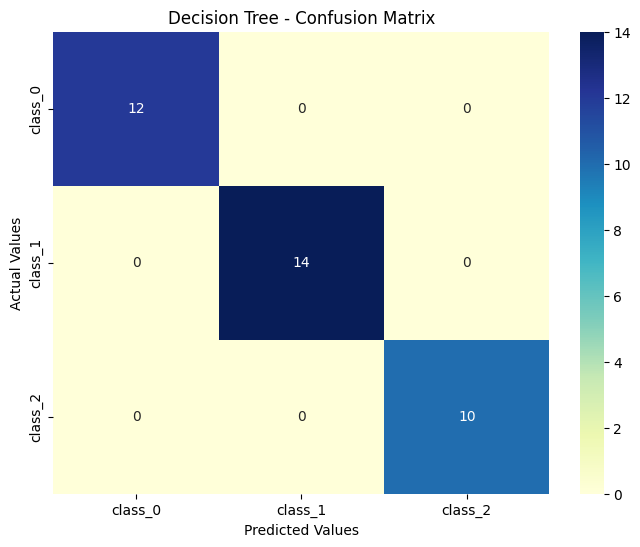

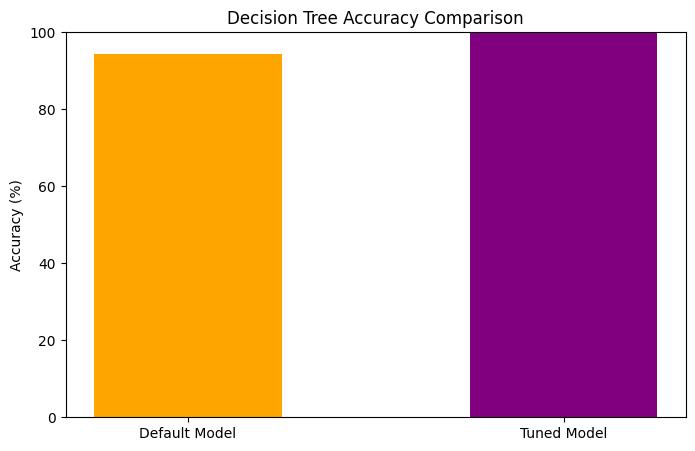

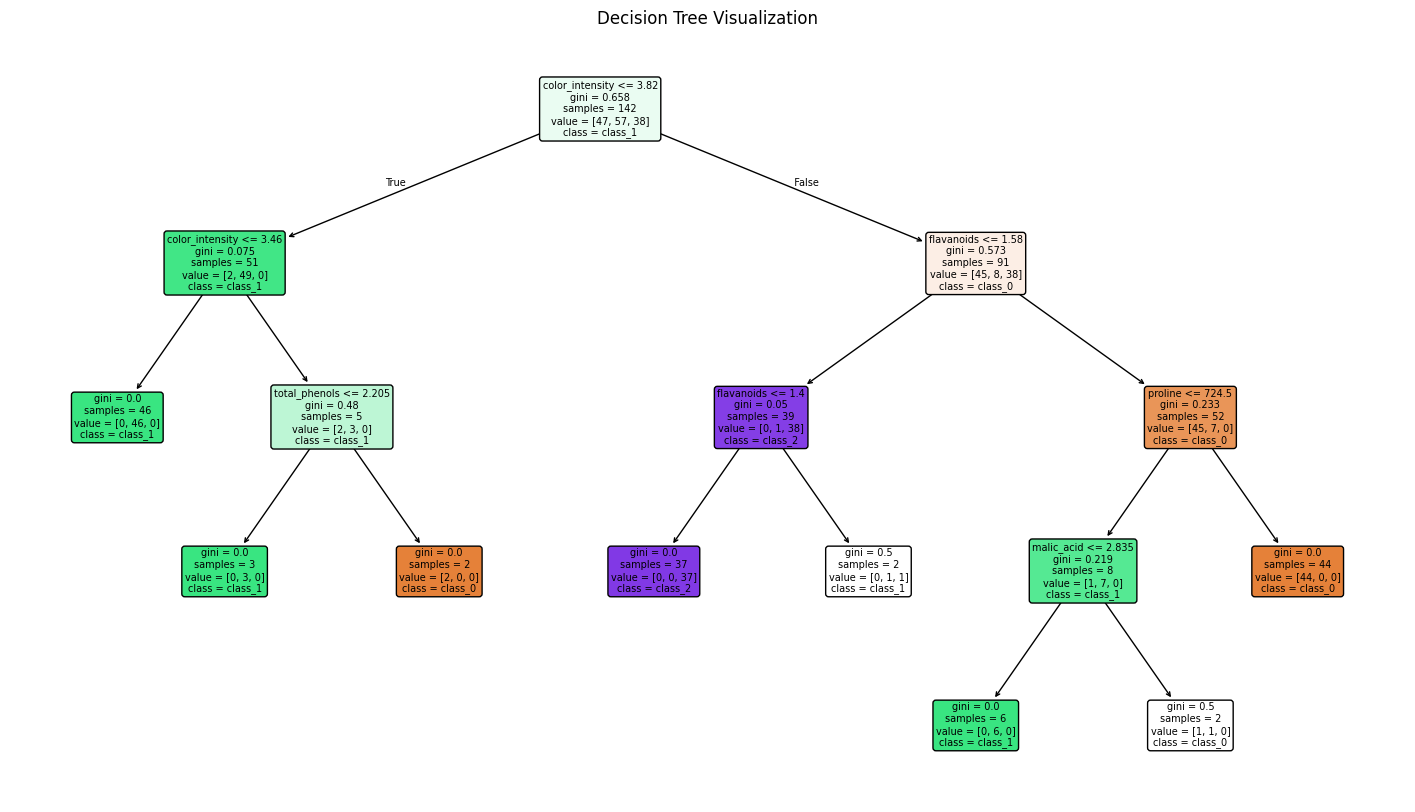

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target)


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


dt_default = DecisionTreeClassifier(random_state=42)


dt_default.fit(X_train, y_train)


y_pred_default = dt_default.predict(X_test)


accuracy_default = accuracy_score(y_test, y_pred_default)

print("----- DEFAULT DECISION TREE -----")
print("Accuracy:", round(accuracy_default * 100, 2), "%")

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt = DecisionTreeClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)


grid_search.fit(X_train, y_train)


best_dt = grid_search.best_estimator_

print("\nBest Parameters:")
print(grid_search.best_params_)


y_pred_tuned = best_dt.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)

print("\n----- TUNED DECISION TREE -----")
print("Accuracy:", round(accuracy_tuned * 100, 2), "%")


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=wine.target_names
))


cm = confusion_matrix(y_test, y_pred_tuned)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()


plt.figure(figsize=(8, 5))

plt.bar(
    ['Default Model', 'Tuned Model'],
    [accuracy_default * 100, accuracy_tuned * 100],
    color=['orange', 'purple'],
    width=0.5
)

plt.title("Decision Tree Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()


plt.figure(figsize=(18, 10))

plot_tree(
    best_dt,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Decision Tree Visualization")
plt.show()